In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("../data/raw/hour.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
df["datetime"] = (
    pd.to_datetime(df["dteday"])
    + pd.to_timedelta(df["hr"], unit="h")
)

df = df.sort_values("datetime").reset_index(drop=True)

print("Start date:", df["datetime"].min())
print("End date:", df["datetime"].max())

display(df[["datetime", "hr", "cnt"]].head())

Start date: 2011-01-01 00:00:00
End date: 2012-12-31 23:00:00


,datetime,hr,cnt
0,2011-01-01 00:00:00,0,16
1,2011-01-01 01:00:00,1,40
2,2011-01-01 02:00:00,2,32
3,2011-01-01 03:00:00,3,13
4,2011-01-01 04:00:00,4,1


In [5]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Target statistics:")
display(df["cnt"].describe())

Missing values:


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
datetime      0
dtype: int64

Duplicate rows: 0
Target statistics:


count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

In [6]:
df["hour_sin"] = np.sin(2 * np.pi * df["hr"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hr"] / 24)

df["month_sin"] = np.sin(2 * np.pi * df["mnth"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["mnth"] / 12)

df["weekday_sin"] = np.sin(
    2 * np.pi * df["weekday"] / 7
)

df["weekday_cos"] = np.cos(
    2 * np.pi * df["weekday"] / 7
)

display(df.head())

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,casual,registered,cnt,datetime,hour_sin,hour_cos,month_sin,month_cos,weekday_sin,weekday_cos
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,3,13,16,2011-01-01 00:00:00,0.000000,1.000000,0.5,0.866025,-0.781831,0.62349
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,8,32,40,2011-01-01 01:00:00,0.258819,0.965926,0.5,0.866025,-0.781831,0.62349
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,5,27,32,2011-01-01 02:00:00,0.500000,0.866025,0.5,0.866025,-0.781831,0.62349
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,3,10,13,2011-01-01 03:00:00,0.707107,0.707107,0.5,0.866025,-0.781831,0.62349
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,0,1,1,2011-01-01 04:00:00,0.866025,0.500000,0.5,0.866025,-0.781831,0.62349


In [7]:
target = "cnt"

categorical_features = [
    "season",
    "yr",
    "mnth",
    "weekday",
    "holiday",
    "workingday",
    "weathersit"
]

numerical_features = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "weekday_sin",
    "weekday_cos"
]

features = categorical_features + numerical_features

X = df[features]
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (17379, 17)
Target: (17379,)


In [8]:
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(df["datetime"].iloc[0])
print(df["datetime"].iloc[split_index - 1])

print("\nTesting period:")
print(df["datetime"].iloc[split_index])
print(df["datetime"].iloc[-1])

Training records: 13903
Testing records: 3476

Training period:
2011-01-01 00:00:00
2012-08-07 11:00:00

Testing period:
2012-08-07 12:00:00
2012-12-31 23:00:00


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [10]:
tscv = TimeSeriesSplit(n_splits=5)

ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]
)

ridge_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best Ridge Alpha:", ridge_search.best_params_)
print("Best CV MAE:", -ridge_search.best_score_)

Best Ridge Alpha: {'model__alpha': 100}
Best CV MAE: 95.59796970608832


In [11]:
ridge_results = pd.DataFrame(
    ridge_search.cv_results_
)

ridge_results["mean_test_MAE"] = (
    -ridge_results["mean_test_score"]
)

display(
    ridge_results[
        [
            "param_model__alpha",
            "mean_test_MAE",
            "std_test_score"
        ]
    ]
)

,param_model__alpha,mean_test_MAE,std_test_score
0,0.01,95.842688,21.766286
1,0.10,95.841978,21.767144
2,1.00,95.836746,21.771903
3,10.00,95.805099,21.773895
4,100.00,95.597970,21.742966
5,1000.00,96.887704,21.969229


In [12]:
lasso_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Lasso(max_iter=20000))
    ]
)

lasso_params = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_params,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

print("Best Lasso Alpha:", lasso_search.best_params_)
print("Best CV MAE:", -lasso_search.best_score_)

Best Lasso Alpha: {'model__alpha': 1}
Best CV MAE: 94.65096246898956


In [13]:
lasso_results = pd.DataFrame(
    lasso_search.cv_results_
)

lasso_results["mean_test_MAE"] = (
    -lasso_results["mean_test_score"]
)

display(
    lasso_results[
        [
            "param_model__alpha",
            "mean_test_MAE",
            "std_test_score"
        ]
    ]
)

,param_model__alpha,mean_test_MAE,std_test_score
0,0.001,95.576687,21.753628
1,0.010,95.514756,21.764980
2,0.100,95.262004,21.673165
3,1.000,94.650962,21.586876
4,10.000,99.643495,23.188621
5,100.000,138.079037,30.752337


In [14]:
ridge_model = ridge_search.best_estimator_
lasso_model = lasso_search.best_estimator_

ridge_predictions = ridge_model.predict(X_test)
lasso_predictions = lasso_model.predict(X_test)

print("Ridge predictions:")
print(ridge_predictions[:10])

print("\nLasso predictions:")
print(lasso_predictions[:10])

Ridge predictions:
[373.26939391 390.93005306 413.07587467 426.42481892 341.65804085
 386.39856608 361.58214627 337.46284704 300.79552546 269.2083743 ]

Lasso predictions:
[371.12302744 388.08031844 407.96357268 419.77820876 349.72399574
 384.4041426  359.17453313 335.89731705 299.18493623 267.72827151]


In [15]:
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2


ridge_mae, ridge_rmse, ridge_r2 = evaluate_model(
    y_test,
    ridge_predictions
)

lasso_mae, lasso_rmse, lasso_r2 = evaluate_model(
    y_test,
    lasso_predictions
)

comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        ridge_mae,
        lasso_mae
    ],
    "RMSE": [
        ridge_rmse,
        lasso_rmse
    ],
    "R2 Score": [
        ridge_r2,
        lasso_r2
    ]
})

display(comparison.round(3))

,Model,MAE,RMSE,R2 Score
0,Ridge Regression,122.188,164.223,0.445
1,Lasso Regression,119.347,165.815,0.434


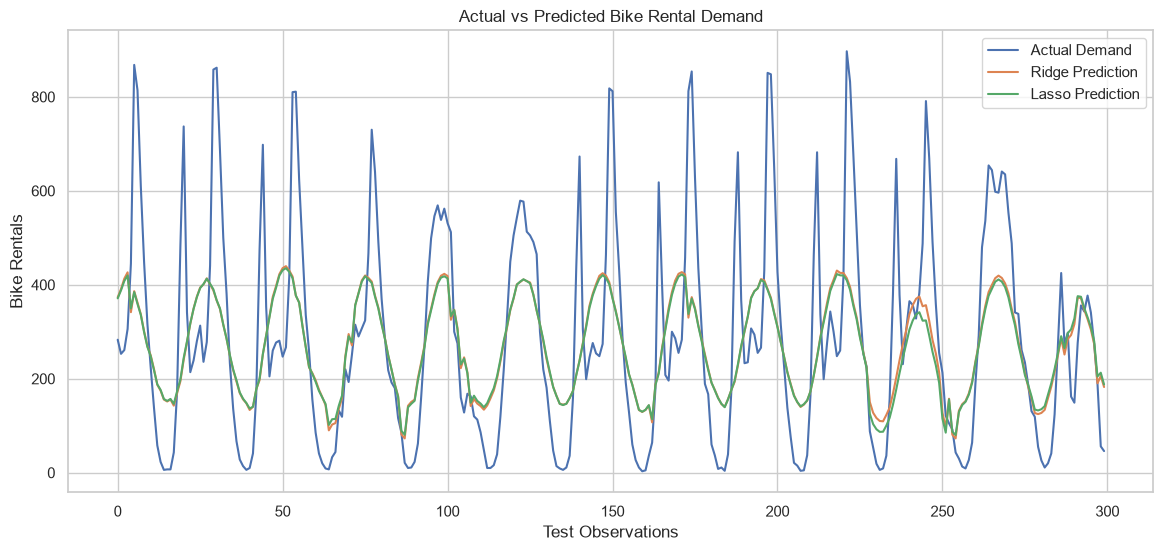

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.iloc[:300].values,
    label="Actual Demand"
)

plt.plot(
    ridge_predictions[:300],
    label="Ridge Prediction"
)

plt.plot(
    lasso_predictions[:300],
    label="Lasso Prediction"
)

plt.title("Actual vs Predicted Bike Rental Demand")
plt.xlabel("Test Observations")
plt.ylabel("Bike Rentals")

plt.legend()
plt.show()

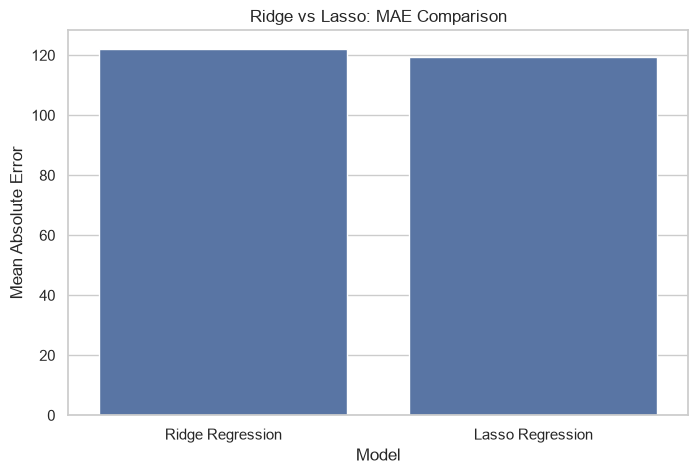

In [17]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="MAE"
)

plt.title("Ridge vs Lasso: MAE Comparison")
plt.ylabel("Mean Absolute Error")

plt.show()

In [18]:
ridge_preprocessor = (
    ridge_model.named_steps["preprocessor"]
)

ridge_estimator = (
    ridge_model.named_steps["model"]
)

feature_names = (
    ridge_preprocessor.get_feature_names_out()
)

ridge_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": ridge_estimator.coef_
})

ridge_coefficients["Absolute Coefficient"] = (
    ridge_coefficients["Coefficient"].abs()
)

ridge_coefficients = ridge_coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(ridge_coefficients.head(15))

,Feature,Coefficient,Absolute Coefficient
5,num__hour_cos,-61.452138,61.452138
4,num__hour_sin,-61.109850,61.109850
15,cat__yr_1,42.223041,42.223041
14,cat__yr_0,-42.223041,42.223041
41,cat__weathersit_3,-37.365055,37.365055
39,cat__weathersit_1,26.451563,26.451563
10,cat__season_1,-21.270567,21.270567
1,num__atemp,20.369987,20.369987
13,cat__season_4,18.373189,18.373189
16,cat__mnth_1,-16.597959,16.597959


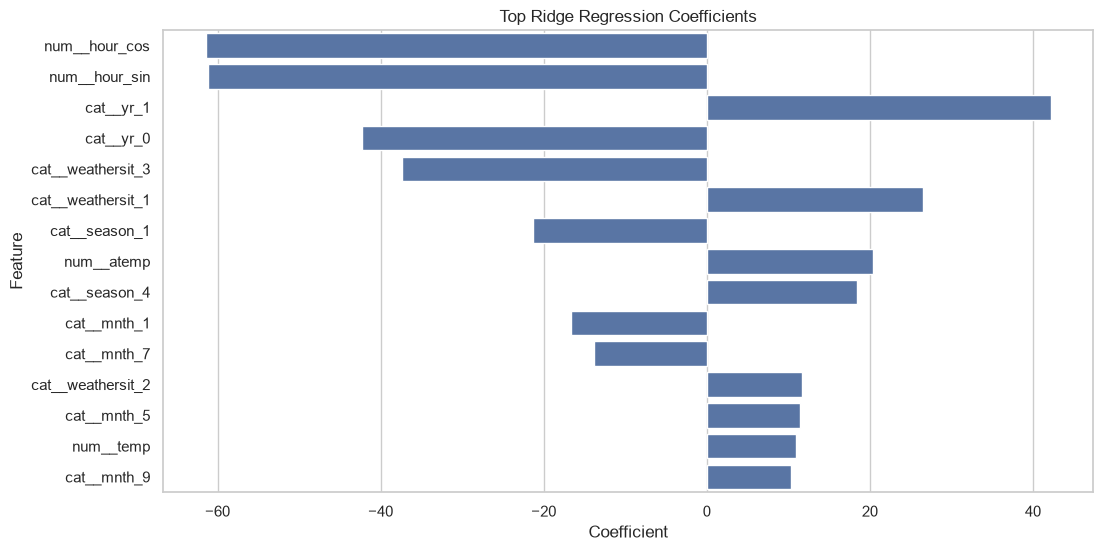

In [19]:
top_features = ridge_coefficients.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top Ridge Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.show()

# Conclusion

In this project, Ridge Regression and Lasso Regression were implemented to predict hourly bike rental demand.

The hourly dataset was sorted chronologically, and time-based feature engineering was performed. Numerical features were standardized, while categorical features were one-hot encoded.

TimeSeriesSplit was used to preserve chronological order during cross-validation. GridSearchCV was used to identify the optimal regularization parameter (alpha) for each model.

Both models were evaluated using MAE, RMSE, and R² Score.

The final comparison helped identify the better-performing model for hourly bike rental demand prediction.

The results provide a foundation for future fleet-rebalancing decisions by helping anticipate periods of high and low demand.

The selected model can be extended in future work to compare against baseline and tree-based models.